# 01 - Exploración de datos

Exploración descriptiva de las dos bases de AMP ya limpias (5-60 aa, 20 aminoácidos estándar, sin duplicados exactos):

- **Antibacterial** (`Antibacterial_amps_clean.fasta`): base principal.
- **general** (`general_amps_clean.fasta`): base de contraste.

La lógica (lectura, composición, carga neta, hidrofobicidad) vive en `src/amp_gan/`; este notebook solo la importa y dibuja. Cuando se comparan las dos bases se usan los mismos ejes y los mismos intervalos (*bins*), y los histogramas se normalizan a fracción de secuencias porque las bases tienen tamaños distintos.

## 0. Preparación: rutas, semilla y versiones

In [1]:
import platform
import random
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Raíz del proyecto: se sube desde el directorio actual hasta encontrar `context/` y `src/` (sin rutas absolutas).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "context").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from amp_gan.data import MAX_LEN, MIN_LEN, STANDARD_ALPHABET, read_fasta
from amp_gan.length_stats import length_summary
from amp_gan.properties import composition_table, properties_table

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROCESSED = ROOT / "context" / "data" / "processed"
PATHS = {
    "Antibacterial": PROCESSED / "Antibacterial_amps_clean.fasta",
    "general": PROCESSED / "general_amps_clean.fasta",
}
COLORS = {"Antibacterial": "tab:blue", "general": "tab:orange"}
NAMES = list(PATHS)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

print("python    :", platform.python_version())
print("numpy     :", np.__version__)
print("pandas    :", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("semilla   :", SEED)

python    : 3.14.8
numpy     : 2.5.3
pandas    : 3.0.6
matplotlib: 3.11.2
semilla   : 42


In [2]:
data = {name: read_fasta(path) for name, path in PATHS.items()}
props = {name: properties_table(df) for name, df in data.items()}
for name in NAMES:
    print(f"{name}: {len(data[name]):,} secuencias")

Antibacterial: 21,754 secuencias
general: 9,391 secuencias


## a. Tamaño y longitud

Número de secuencias por base y distribución de longitudes. El histograma usa un intervalo por cada longitud entera (5-60 aa) y fracción de secuencias en el eje y, con ejes compartidos.

,n,media,mediana,desv. típica,moda,mín,máx
base,,,,,,,
Antibacterial,21754,21.12,20.0,11.97,20,5,60
general,9391,22.62,19.0,12.19,13,5,60


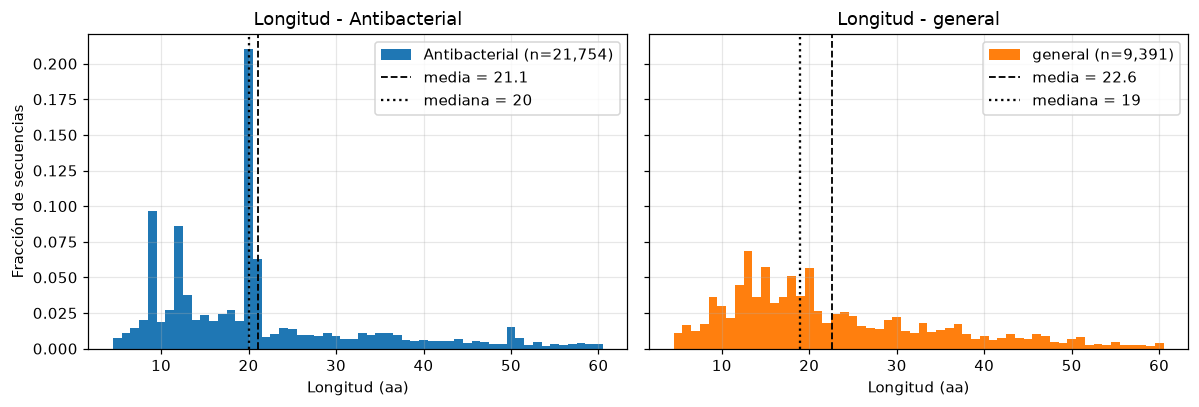

In [3]:
rows = []
for name in NAMES:
    s = length_summary(props[name]["length"])
    rows.append({"base": name, "n": s["n"], "media": s["mean"], "mediana": s["median"], "desv. típica": s["std"],
                 "moda": s["mode"], "mín": s["min"], "máx": s["max"]})
display(pd.DataFrame(rows).set_index("base").round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True, sharey=True)
bins = np.arange(MIN_LEN, MAX_LEN + 2) - 0.5
for ax, name in zip(axes, NAMES):
    lengths = props[name]["length"].to_numpy()
    ax.hist(lengths, bins=bins, weights=np.full(lengths.size, 1 / lengths.size), color=COLORS[name],
            label=f"{name} (n={lengths.size:,})")
    ax.axvline(lengths.mean(), color="k", ls="--", lw=1.2, label=f"media = {lengths.mean():.1f}")
    ax.axvline(np.median(lengths), color="k", ls=":", lw=1.5, label=f"mediana = {np.median(lengths):.0f}")
    ax.set_title(f"Longitud - {name}")
    ax.set_xlabel("Longitud (aa)")
    ax.legend()
axes[0].set_ylabel("Fracción de secuencias")
fig.tight_layout()
plt.show()

## b. Composición de aminoácidos

Fracción media de cada aminoácido (media de las fracciones por secuencia) en ambas bases, ordenados de mayor a menor en Antibacterial.

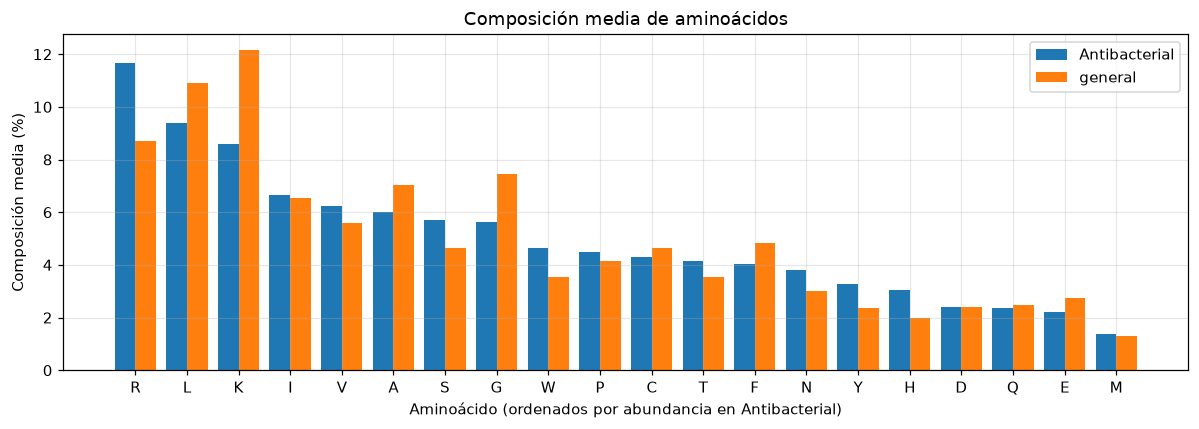

Antibacterial: más abundantes = R 11.7%, L 9.4%, K 8.6%, I 6.7%, V 6.2% | menos abundantes = M 1.4%, E 2.2%, Q 2.4%
general: más abundantes = K 12.2%, L 10.9%, R 8.7%, G 7.5%, A 7.0% | menos abundantes = M 1.3%, H 2.0%, Y 2.4%


In [4]:
comp = pd.DataFrame({name: composition_table(data[name]["sequence"]).set_index("amino_acid")["mean_fraction"]
                     for name in NAMES})
comp = comp.sort_values("Antibacterial", ascending=False)

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(comp))
w = 0.4
for i, name in enumerate(NAMES):
    ax.bar(x + (i - 0.5) * w, comp[name] * 100, width=w, color=COLORS[name], label=name)
ax.set_xticks(x)
ax.set_xticklabels(comp.index)
ax.set_xlabel("Aminoácido (ordenados por abundancia en Antibacterial)")
ax.set_ylabel("Composición media (%)")
ax.set_title("Composición media de aminoácidos")
ax.legend()
fig.tight_layout()
plt.show()

for name in NAMES:
    top = comp[name].sort_values(ascending=False).head(5)
    low = comp[name].sort_values().head(3)
    print(f"{name}: más abundantes = " + ", ".join(f"{aa} {v*100:.1f}%" for aa, v in top.items())
          + " | menos abundantes = " + ", ".join(f"{aa} {v*100:.1f}%" for aa, v in low.items()))

Nota: en Antibacterial dominan R, L y K, seguidos de I y V; en general dominan K, L y R, seguidos de G y A. En las dos bases los tres residuos más abundantes (R, K, L) suman alrededor de un 30 % de la composición media, y M es el menos abundante.

## c. Carga neta a pH 7,4 e hidrofobicidad

Carga neta por Henderson-Hasselbalch (pKa de EMBOSS, ver docstring de `net_charge`) e hidrofobicidad media de Kyte-Doolittle (GRAVY). Histogramas con los mismos intervalos y ejes en ambas bases (la carga neta no es entera, por eso se agrupa en intervalos de 1); el rango del eje de la carga se limita a los percentiles 0,5-99,5 conjuntos y se indica cuántas secuencias quedan fuera de la vista.

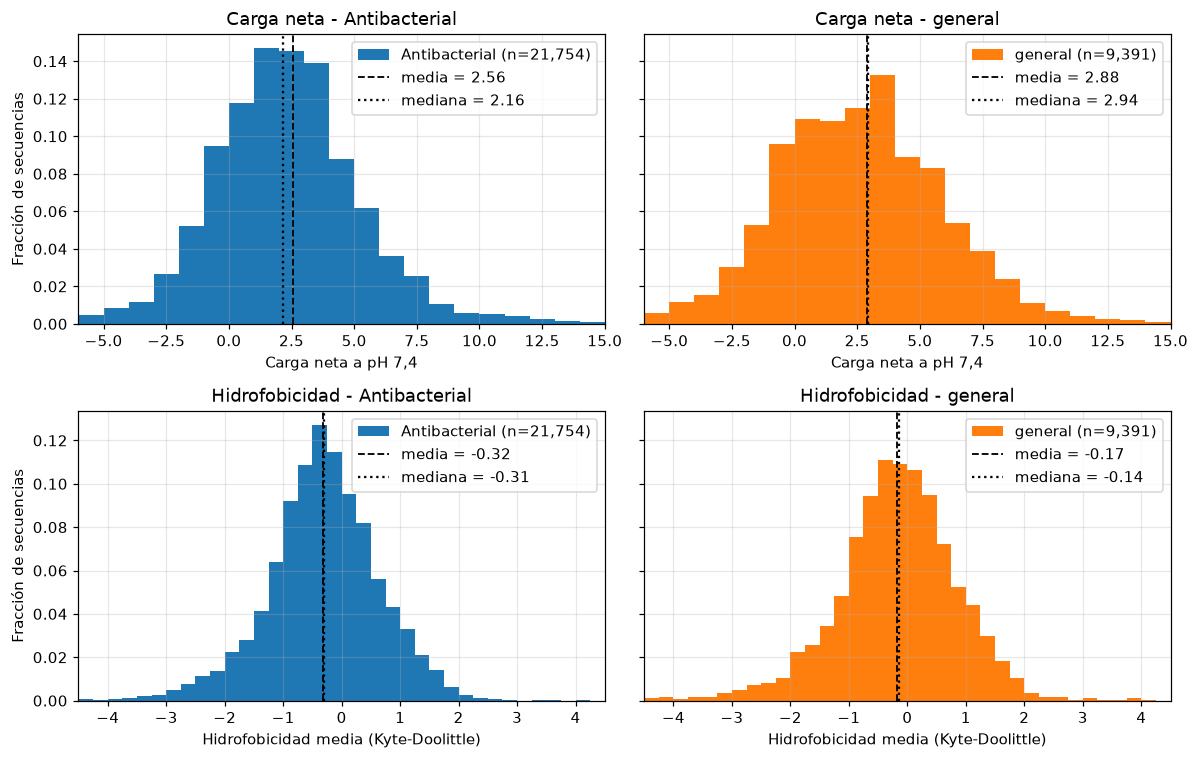

Antibacterial: fuera de la vista -> carga fuera de [-6, 15]: 211 secuencias; hidrofobicidad fuera de [-4.5, 4.5]: 0 secuencias
general: fuera de la vista -> carga fuera de [-6, 15]: 68 secuencias; hidrofobicidad fuera de [-4.5, 4.5]: 0 secuencias


In [5]:
all_charge = np.concatenate([props[n]["net_charge"].to_numpy() for n in NAMES])
lo, hi = np.floor(np.percentile(all_charge, 0.5)), np.ceil(np.percentile(all_charge, 99.5))
charge_bins = np.arange(lo, hi + 1.0, 1.0)
hyd_bins = np.arange(-4.5, 4.5 + 0.01, 0.25)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey="row")
for j, name in enumerate(NAMES):
    for i, (col, bins_, xlabel, ttl) in enumerate([
        ("net_charge", charge_bins, "Carga neta a pH 7,4", "Carga neta"),
        ("hydrophobicity", hyd_bins, "Hidrofobicidad media (Kyte-Doolittle)", "Hidrofobicidad"),
    ]):
        v = props[name][col].to_numpy()
        ax = axes[i, j]
        ax.hist(v, bins=bins_, weights=np.full(v.size, 1 / v.size), color=COLORS[name], label=f"{name} (n={v.size:,})")
        ax.axvline(v.mean(), color="k", ls="--", lw=1.2, label=f"media = {v.mean():.2f}")
        ax.axvline(np.median(v), color="k", ls=":", lw=1.5, label=f"mediana = {np.median(v):.2f}")
        ax.set_xlim(bins_[0], bins_[-1])
        ax.set_xlabel(xlabel)
        ax.set_title(f"{ttl} - {name}")
        ax.legend()
for i in range(2):
    axes[i, 0].set_ylabel("Fracción de secuencias")
fig.tight_layout()
plt.show()

for name in NAMES:
    c = props[name]["net_charge"]
    h = props[name]["hydrophobicity"]
    n_c = int(((c < charge_bins[0]) | (c > charge_bins[-1])).sum())
    n_h = int(((h < hyd_bins[0]) | (h > hyd_bins[-1])).sum())
    print(f"{name}: fuera de la vista -> carga fuera de [{charge_bins[0]:.0f}, {charge_bins[-1]:.0f}]: {n_c} secuencias; "
          f"hidrofobicidad fuera de [{hyd_bins[0]:.1f}, {hyd_bins[-1]:.1f}]: {n_h} secuencias")

In [6]:
def summarize(s: pd.Series) -> dict[str, float]:
    return {"media": s.mean(), "mediana": s.median(), "desv. típica": s.std(ddof=1),
            "p5": s.quantile(0.05), "p95": s.quantile(0.95)}

summary = pd.concat({name: pd.DataFrame({"carga neta": summarize(props[name]["net_charge"]),
                                         "hidrofobicidad": summarize(props[name]["hydrophobicity"])}).T
                     for name in NAMES}, names=["base", "propiedad"])
display(summary.round(3))
for name in NAMES:
    c = props[name]["net_charge"]
    print(f"{name}: carga neta > 0: {100 * (c > 0).mean():.1f} % | carga neta >= 2: {100 * (c >= 2).mean():.1f} % | carga neta < 0: {100 * (c < 0).mean():.1f} %")

media  mediana  desv. típica     p5    p95
base          propiedad                                                 
Antibacterial carga neta      2.558    2.164         3.214 -2.058  7.794
              hidrofobicidad -0.316   -0.308         0.943 -1.941  1.217
general       carga neta      2.882    2.937         3.436 -2.132  8.627
              hidrofobicidad -0.175   -0.144         1.017 -1.896  1.379

Antibacterial: carga neta > 0: 79.6 % | carga neta >= 2: 53.1 % | carga neta < 0: 20.4 %
general: carga neta > 0: 78.4 % | carga neta >= 2: 56.7 % | carga neta < 0: 21.6 %


## d. Relación carga-hidrofobicidad

Mapa de densidad 2D (fracción de secuencias por celda, escala logarítmica común) de la carga neta frente a la hidrofobicidad, con los mismos ejes y la misma escala de color en las dos bases. Se indica además el coeficiente de correlación de Pearson (calculado con todas las secuencias; el mapa solo dibuja las que caen en el rango de ejes del apartado c).

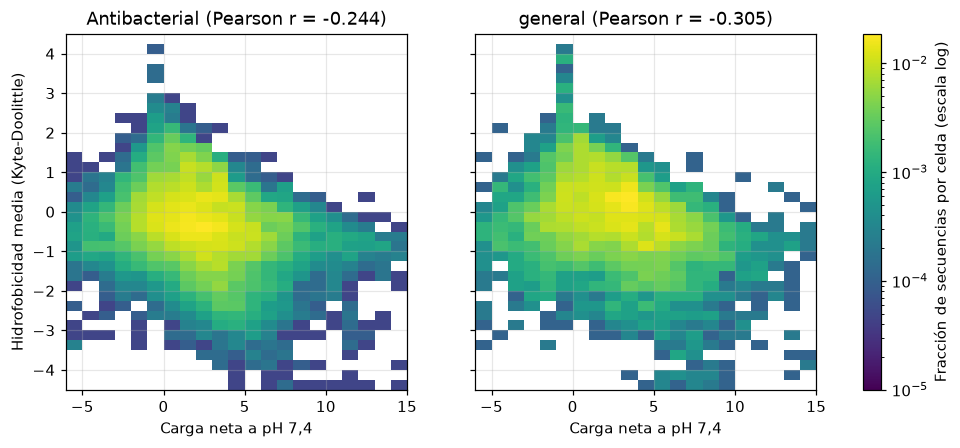

In [7]:
x_edges = np.arange(lo, hi + 1.0, 1.0)
y_edges = np.arange(-4.5, 4.5 + 0.01, 0.25)
hists = {}
for name in NAMES:
    H, _, _ = np.histogram2d(props[name]["net_charge"], props[name]["hydrophobicity"], bins=[x_edges, y_edges])
    hists[name] = H / H.sum()
vmax = max(h.max() for h in hists.values())
norm = matplotlib.colors.LogNorm(vmin=1e-5, vmax=vmax)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, name in zip(axes, NAMES):
    H = np.ma.masked_where(hists[name] == 0, hists[name])
    mesh = ax.pcolormesh(x_edges, y_edges, H.T, norm=norm, cmap="viridis")
    r = np.corrcoef(props[name]["net_charge"], props[name]["hydrophobicity"])[0, 1]
    ax.set_title(f"{name} (Pearson r = {r:.3f})")
    ax.set_xlabel("Carga neta a pH 7,4")
fig.colorbar(mesh, ax=axes, label="Fracción de secuencias por celda (escala log)")
axes[0].set_ylabel("Hidrofobicidad media (Kyte-Doolittle)")
plt.show()

## e. Solapamiento entre las dos bases

Cuántas secuencias de `general` (ya limpia) aparecen, por secuencia exacta, en `Antibacterial` (ya limpia).

Secuencias en general            : 9,391
Secuencias en Antibacterial      : 21,754
De general presentes en Antibacterial: 4,965 (52.87 % de general)
Solo en general                  : 4,426 (47.13 % de general)
Compartidas / Antibacterial      : 22.82 %


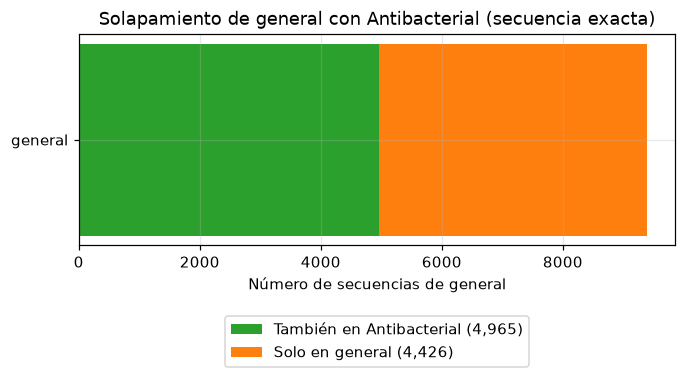

In [8]:
seq_anti = set(data["Antibacterial"]["sequence"])
seq_gen = set(data["general"]["sequence"])
shared = seq_gen & seq_anti
print(f"Secuencias en general            : {len(seq_gen):,}")
print(f"Secuencias en Antibacterial      : {len(seq_anti):,}")
print(f"De general presentes en Antibacterial: {len(shared):,} ({100 * len(shared) / len(seq_gen):.2f} % de general)")
print(f"Solo en general                  : {len(seq_gen - seq_anti):,} ({100 * len(seq_gen - seq_anti) / len(seq_gen):.2f} % de general)")
print(f"Compartidas / Antibacterial      : {100 * len(shared) / len(seq_anti):.2f} %")

fig, ax = plt.subplots(figsize=(7, 4))
vals = [len(shared), len(seq_gen - seq_anti)]
ax.barh(["general"], [vals[0]], color="tab:green", label=f"También en Antibacterial ({vals[0]:,})")
ax.barh(["general"], [vals[1]], left=[vals[0]], color=COLORS["general"], label=f"Solo en general ({vals[1]:,})")
ax.set_xlabel("Número de secuencias de general")
ax.set_title("Solapamiento de general con Antibacterial (secuencia exacta)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3))
fig.subplots_adjust(bottom=0.4, top=0.88)
plt.show()

## f. Conclusiones (descriptivas)

Observaciones de esta ejecución (datos limpios de DRAMP 5.0; cifras redondeadas, ver las celdas anteriores):

- **Tamaño y longitud.** Antibacterial tiene 21 754 secuencias y general 9 391. Longitud media 21,1 aa (mediana 20) en Antibacterial y 22,6 aa (mediana 19) en general. Antibacterial concentra picos marcados en 20 aa (21,0 % de sus secuencias), 9 aa (9,7 %) y 12 aa (8,6 %); general tiene una distribución más repartida, con máximo en 13 aa (6,8 %).
- **Composición.** En Antibacterial los aminoácidos más abundantes son R (11,7 %), L (9,4 %), K (8,6 %), I y V; en general, K (12,2 %), L (10,9 %), R (8,7 %), G y A. Los menos abundantes en ambas bases incluyen M (~1,3-1,4 %). R es más abundante en Antibacterial que en general; K, L, G y A lo son más en general.
- **Carga neta y hidrofobicidad.** Carga neta media 2,56 (Antibacterial) y 2,88 (general); el 79,6 % y el 78,4 % de las secuencias, respectivamente, tienen carga neta positiva a pH 7,4. Hidrofobicidad media (Kyte-Doolittle) de -0,32 y -0,17: en ambas bases la mayoría de las secuencias tiene valores cercanos a 0 o ligeramente negativos, y las distribuciones de general están algo desplazadas hacia valores más altos de hidrofobicidad.
- **Carga-hidrofobicidad.** En ambas bases hay una correlación de Pearson negativa y débil (r = -0,244 en Antibacterial y -0,305 en general). La mayor densidad de secuencias se sitúa con carga neta entre 0 y 5 e hidrofobicidad entre -1 y 0,5.
- **Solapamiento.** 4 965 de las 9 391 secuencias de general (52,87 %) están también, por secuencia exacta, en Antibacterial (22,82 % de Antibacterial); 4 426 (47,13 %) solo están en general.
